# Notebook 2: LSIS-AFS Error Correction

**LunaLink Reference Implementation — Pedagogical Notebook Series**

This notebook teaches the **forward error correction (FEC)** layer of the
[LunaNet](https://www.nasa.gov/humans-in-space/lunanet-empowering-artemis-with-communications-and-navigation-interoperability/) Signal-In-Space
Augmented Forward Signal (LSIS-AFS). By the end, you will understand how
navigation messages are protected against channel errors — from encoding through
decoding — and be able to run the full TX→RX pipeline yourself.

> **Spec reference:** LSIS-AFS Volume A, V1.0, §2.4 — *Navigation Message Structure*
> ([CCSDS](https://ccsds.org/), 29 January 2025)

### What you will learn

| Section | Topic | Spec section |
|---------|-------|-------------|
| 1 | Frame structure — how 6,000 symbols are organised | §2.4.1, Table 14 |
| 2 | BCH(51,8) — header encoding for SB1 | §2.4.2 (LSIS-310) |
| 3 | CRC-24 — message integrity check | §2.4.3.1.2 (LSIS-340) |
| 4 | LDPC — low-density parity-check codes for SB2–SB4 | §2.4.3.1.3–5 (LSIS-320) |
| 5 | Sum-product decoding — the φ-transform | §2.4.3.1.3 |
| 6 | Decoding through noise — AWGN channel | — |
| 7 | Block interleaving — burst error resilience | §2.4.3.1.6 (LSIS-330) |
| 8–9 | Waterfall & convergence (pre-computed) | — |
| 10 | Full pipeline — end-to-end round-trip | §2.4.3 |
| 11–12 | Error forensics & spec compliance | — |

### Prerequisites

```
pip install lunalink matplotlib
```

### Background reading

- **Channel coding theory:** Shannon,
  ["A Mathematical Theory of Communication"](https://doi.org/10.1002/j.1538-7305.1948.tb01338.x)
  (*Bell System Technical Journal*, 1948) — the founding paper.
- **LDPC codes:** Gallager,
  ["Low-Density Parity-Check Codes"](https://doi.org/10.1109/TIT.1962.1057683)
  (*IRE Trans. Information Theory*, 1962) — invented LDPC 60 years before hardware caught up.
- **BCH codes:** Bose & Ray-Chaudhuri,
  ["On a Class of Error Correcting Binary Group Codes"](https://doi.org/10.1016/S0019-9958%2860%2990287-4)
  (*Information and Control*, 1960).
- **5G NR LDPC:** Richardson & Urbanke,
  [*Modern Coding Theory*](https://openlibrary.org/isbn/9780521852296)
  (Cambridge University Press, 2008) — the textbook behind 3GPP's LDPC design.
- **GNSS FEC:** Kaplan & Hegarty,
  [*Understanding GPS/GNSS: Principles and Applications*](https://openlibrary.org/isbn/9781630810580)
  (Artech House, 3rd ed., 2017), Ch. 5.

In [1]:
import json  # Load pre-computed data
import math  # erfc for uncoded BPSK
from pathlib import Path  # File paths

import matplotlib.pyplot as plt  # Plotting
import numpy as np  # Arrays

from lunalink.afs import (  # LunaLink API
    INTERLEAVER_COLS,  # 98 columns
    INTERLEAVER_ROWS,  # 60 rows
    INTERLEAVER_SIZE,  # 5880 symbols
    SB3_DATA_BITS,  # 846 data bits
    BchStatus,  # BCH status codes
    LdpcSubframe,  # SF2, SF3, SF4
    bch_decode,  # BCH hard decoder
    bch_decode_soft,  # BCH soft decoder
    bch_encode,  # BCH encoder
    block_deinterleave,  # 60x98 deinterleaver
    block_interleave,  # 60x98 interleaver
    crc24_calculate,  # CRC-24 generator
    crc24_verify,  # CRC-24 checker
    ldpc_decode,  # LDPC SP decoder
    ldpc_encode,  # LDPC encoder
)

---

## Why error correction?

A navigation satellite transmits at very low power over enormous distances.
By the time the signal reaches a lunar receiver, it is buried in
[thermal noise](https://en.wikipedia.org/wiki/Thermal_noise) — the raw
[bit error rate (BER)](https://en.wikipedia.org/wiki/Bit_error_rate) can
easily exceed 10%.

[Forward error correction (FEC)](https://en.wikipedia.org/wiki/Forward_error_correction)
adds structured redundancy *before* transmission so the receiver can detect
and correct errors *without* retransmission — critical when a round-trip
to the Moon takes over 2.5 seconds.

[Shannon's channel capacity theorem](https://en.wikipedia.org/wiki/Noisy-channel_coding_theorem) (1948) proves that error-free communication is possible at any rate below
the channel capacity $C = B \log_2(1 + \text{SNR})$, provided sufficiently
clever coding. LSIS-AFS gets close to this limit using a modern
[LDPC code](https://en.wikipedia.org/wiki/Low-density_parity-check_code)
— within ~1.0 dB of the Shannon limit.

**Let's see error correction in action before diving into the details:**

---

## 1. Frame structure

> **Spec:** §2.4.1, Table 14 — *Navigation Message Structure*

Before we look at each FEC component, let's see how they fit together.
An LSIS-AFS **frame** is 6,000 symbols long (12 seconds at 500 symbols/second)
and has three parts:

| Field | Symbols | Encoding | Purpose |
|-------|---------|----------|---------|
| Sync Pattern (SP) | 68 | None (fixed) | Frame synchronisation |
| Subframe 1 (SB1) | 52 | BCH(51,8) | Frame ID + Time of Interval |
| Payload (SB2+SB3+SB4) | 5,880 | CRC-24 → LDPC → interleave | Navigation data |
| **Total** | **6,000** | | **12.0 seconds** |

The payload is the concatenation of three LDPC-encoded subframes (SB2: 2,400 +
SB3: 1,740 + SB4: 1,740 = 5,880 symbols), passed through a 60×98
[block interleaver](https://en.wikipedia.org/wiki/Burst_error-correcting_code#Block_interleaver)
before transmission.

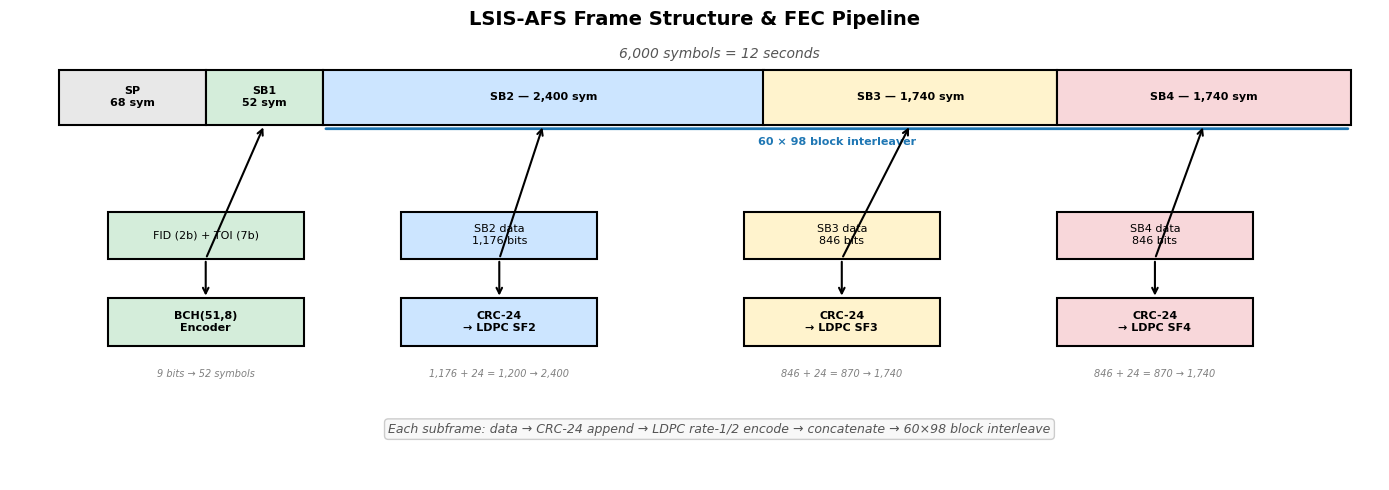

In [2]:
# --- Frame structure diagram ---

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5.5)
ax.axis("off")
ax.set_title(
    "LSIS-AFS Frame Structure & FEC Pipeline", fontsize=14, fontweight="bold", pad=15
)


def box(x, y, w, h, text, color="white", ec="black", fontsize=9, bold=False):
    ax.add_patch(
        plt.Rectangle(
            (x, y), w, h, facecolor=color, edgecolor=ec, linewidth=1.5, zorder=2
        )
    )
    weight = "bold" if bold else "normal"
    ax.text(
        x + w / 2,
        y + h / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight=weight,
        zorder=3,
    )


def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    )


# Frame bar at top
box(0.5, 4.5, 1.5, 0.7, "SP\n68 sym", color="#E8E8E8", fontsize=8, bold=True)
box(2.0, 4.5, 1.2, 0.7, "SB1\n52 sym", color="#D4EDDA", fontsize=8, bold=True)
box(3.2, 4.5, 4.5, 0.7, "SB2 — 2,400 sym", color="#CCE5FF", fontsize=8, bold=True)
box(7.7, 4.5, 3.0, 0.7, "SB3 — 1,740 sym", color="#FFF3CD", fontsize=8, bold=True)
box(10.7, 4.5, 3.0, 0.7, "SB4 — 1,740 sym", color="#F8D7DA", fontsize=8, bold=True)
ax.text(
    7.25,
    5.35,
    "6,000 symbols = 12 seconds",
    ha="center",
    fontsize=10,
    style="italic",
    color="#555",
)

# Interleaver bracket
ax.annotate(
    "",
    xy=(3.2, 4.45),
    xytext=(13.7, 4.45),
    arrowprops=dict(arrowstyle="-", color="C0", lw=2),
)
ax.text(
    8.45,
    4.25,
    "60 × 98 block interleaver",
    ha="center",
    fontsize=8,
    color="C0",
    fontweight="bold",
)

# SB1 pipeline (left)
box(1.0, 2.8, 2.0, 0.6, "FID (2b) + TOI (7b)", color="#D4EDDA", fontsize=8)
arrow(2.0, 2.8, 2.0, 2.3)
box(1.0, 1.7, 2.0, 0.6, "BCH(51,8)\nEncoder", color="#D4EDDA", fontsize=8, bold=True)
arrow(2.0, 2.8, 2.6, 4.5)
ax.text(
    2.0,
    1.3,
    "9 bits → 52 symbols",
    ha="center",
    fontsize=7,
    color="gray",
    style="italic",
)

# SB2 pipeline (middle)
box(4.0, 2.8, 2.0, 0.6, "SB2 data\n1,176 bits", color="#CCE5FF", fontsize=8)
arrow(5.0, 2.8, 5.0, 2.3)
box(4.0, 1.7, 2.0, 0.6, "CRC-24\n→ LDPC SF2", color="#CCE5FF", fontsize=8, bold=True)
arrow(5.0, 2.8, 5.45, 4.5)
ax.text(
    5.0,
    1.3,
    "1,176 + 24 = 1,200 → 2,400",
    ha="center",
    fontsize=7,
    color="gray",
    style="italic",
)

# SB3 pipeline
box(7.5, 2.8, 2.0, 0.6, "SB3 data\n846 bits", color="#FFF3CD", fontsize=8)
arrow(8.5, 2.8, 8.5, 2.3)
box(7.5, 1.7, 2.0, 0.6, "CRC-24\n→ LDPC SF3", color="#FFF3CD", fontsize=8, bold=True)
arrow(8.5, 2.8, 9.2, 4.5)
ax.text(
    8.5,
    1.3,
    "846 + 24 = 870 → 1,740",
    ha="center",
    fontsize=7,
    color="gray",
    style="italic",
)

# SB4 pipeline
box(10.7, 2.8, 2.0, 0.6, "SB4 data\n846 bits", color="#F8D7DA", fontsize=8)
arrow(11.7, 2.8, 11.7, 2.3)
box(10.7, 1.7, 2.0, 0.6, "CRC-24\n→ LDPC SF4", color="#F8D7DA", fontsize=8, bold=True)
arrow(11.7, 2.8, 12.2, 4.5)
ax.text(
    11.7,
    1.3,
    "846 + 24 = 870 → 1,740",
    ha="center",
    fontsize=7,
    color="gray",
    style="italic",
)

# Bottom label
ax.text(
    7.25,
    0.6,
    "Each subframe: data → CRC-24 append → LDPC rate-1/2 encode → "
    "concatenate → 60×98 block interleave",
    ha="center",
    fontsize=9,
    style="italic",
    color="#555",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#f8f8f8", edgecolor="#ccc"),
)

fig.tight_layout()
plt.show()

---

## 2. BCH(51,8) — Subframe 1 header encoding

> **Spec:** §2.4.2 (LSIS-310) — *Subframe 1 Encoding*

[BCH codes](https://en.wikipedia.org/wiki/BCH_code) (Bose–Chaudhuri–Hocquenghem)
are a family of [cyclic error-correcting codes](https://en.wikipedia.org/wiki/Cyclic_code)
defined by a
[generator polynomial](https://en.wikipedia.org/wiki/Generator_polynomial).

LSIS-AFS uses a **BCH(51,8)** code for the frame header (Subframe 1). The header
carries just 9 bits of information — the **Frame ID** (FID, 2 bits) and
**Time of Interval** (TOI, 7 bits) — but these must be decoded reliably even
at very low SNR, because they tell the receiver *which* frame it is looking at.

**Parameters:**

| Parameter | Value | Source |
|-----------|-------|--------|
| Generator polynomial | $g(x) = x^8 + x^7 + x^6 + x^5 + x^4 + x + 1$ (0x1F3) | §2.4.2 |
| Data bits | 9 (FID + TOI) | LSIS-310 |
| Codeword length | 52 symbols | Table 14 |
| Error correction capability | up to **2 bit errors** | — |
| Code rate | 9/52 ≈ 0.173 (very low — heavy protection) | — |

The low code rate means BCH uses ~5.8× redundancy — acceptable for 52 symbols
but would be wasteful for the larger subframes (which use LDPC instead).

Let's encode a header and inspect the codeword:

In [3]:
# Encode a BCH codeword for FID=0, TOI=42
codeword = bch_encode(fid=0, toi=42)
print(f"Codeword length:  {len(codeword)} symbols")
print(f"First 20 symbols: {list(codeword[:20])}")

# Decode it back — should recover perfectly
result = bch_decode(codeword)
print(f"\nDecoded FID={result.fid}, TOI={result.toi}, status={result.status}")

Codeword length:  52 symbols
First 20 symbols: [np.uint8(0), np.uint8(0), np.uint8(0), np.uint8(1), np.uint8(0), np.uint8(1), np.uint8(0), np.uint8(1), np.uint8(0), np.uint8(0), np.uint8(0), np.uint8(1), np.uint8(1), np.uint8(1), np.uint8(0), np.uint8(0), np.uint8(0), np.uint8(1), np.uint8(0), np.uint8(1)]

Decoded FID=Fid(0), TOI=Toi(42), status=BchStatus.OK


### Error correction in action

Let's flip some bits and see if BCH can recover the original message:

In [4]:
# Inject 1 and 2 bit errors — BCH should correct both
for n_errors in [0, 1, 2, 3]:
    corrupted = np.array(codeword, dtype=np.uint8)
    # Flip the first n_errors bits
    for i in range(n_errors):
        corrupted[i] ^= 1

    result = bch_decode(corrupted)
    status = "OK" if result.status.name == "OK" else result.status.name
    recovered = f"FID={result.fid}, TOI={result.toi}" if status == "OK" else "—"
    print(f"{n_errors} error(s): status={status:20s} recovered={recovered}")

0 error(s): status=OK                   recovered=FID=Fid(0), TOI=Toi(42)
1 error(s): status=OK                   recovered=FID=Fid(0), TOI=Toi(42)
2 error(s): status=OK                   recovered=FID=Fid(0), TOI=Toi(42)
3 error(s): status=NULL_OUTPUT          recovered=—


BCH(51,8) corrects up to 2 errors. At 3 errors, decoding fails — the receiver
falls back to the CRC or reports a sync failure. This is by design: SB1 is
short (52 symbols out of 6000), so the probability of 3+ errors in just those
52 symbols is extremely low at the operating SNR.

### Hard vs soft decisions: why analog matters

When a BPSK symbol arrives at the receiver, the correlator outputs an
**analog voltage** — say, +0.8 or −0.3. There are two ways to use this:

- **Hard decision:** Throw away the amplitude. If positive → bit 0,
  if negative → bit 1. The decoder sees only `0` and `1` — it has no
  idea that +0.8 was much more confident than +0.1.

- **Soft decision:** Pass the analog value to the decoder as a
  [log-likelihood ratio (LLR)](https://en.wikipedia.org/wiki/Log-likelihood_ratio):
  `L = 2y/σ²`. A large positive LLR means "very likely bit 0";
  a small positive LLR means "barely bit 0." The decoder uses this
  **confidence** to make better choices about which bits to flip.

The plot below shows the dramatic difference: the soft-decision decoder
achieves 50% correct decoding at a much lower SNR than hard-decision.
The gap is large because BCH(51,8) is a short code where the maximum-likelihood
search over all 2⁸ = 256 codewords benefits enormously from knowing *how confident*
each bit is, not just its sign.

This principle applies to all FEC in LSIS-AFS: BCH should use soft
decisions for SB1, and the LDPC decoder (sections below) is *inherently*
soft — its belief propagation messages are LLRs, not bits.

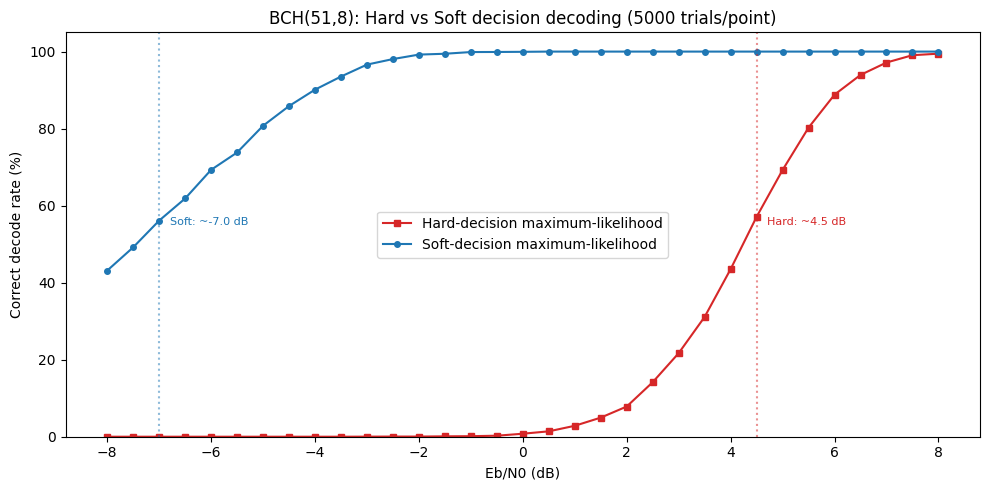


The gap between the dotted lines shows the cost of throwing away
analog confidence. For this short code, soft-decision maximum-likelihood
gains enormously because it searches all 256 codewords weighted by LLR.

This is why any LSIS-AFS receiver should use soft-decision decoding.


In [5]:
# --- Soft-decision BCH: the value of analog confidence ---
# Compare hard-decision (binary) vs soft-decision (LLR) BCH decoding.

rng = np.random.default_rng(123)
fid, toi = 3, 99
codeword = bch_encode(fid, toi)
bipolar = 1.0 - 2.0 * codeword.astype(np.float64)  # BPSK: 0→+1, 1→-1

n_trials = 5000
snr_db_range = np.arange(-8.0, 8.1, 0.5)

hard_success = np.zeros(len(snr_db_range))
soft_success = np.zeros(len(snr_db_range))

for i, snr_db in enumerate(snr_db_range):
    sigma = 10 ** (-snr_db / 20)
    for _ in range(n_trials):
        noise = rng.normal(0, sigma, len(bipolar))
        received = bipolar + noise

        # Hard decision: threshold at 0, then decode binary
        hard_bits = (received < 0).astype(np.uint8)
        h_result = bch_decode(hard_bits)
        if (
            h_result.status == BchStatus.OK
            and int(h_result.fid) == fid
            and int(h_result.toi) == toi
        ):
            hard_success[i] += 1

        # Soft decision: pass LLRs directly (L = 2y/sigma^2, positive favours bit 0)
        llr = (2.0 * received / (sigma * sigma)).astype(np.float32)
        s_result = bch_decode_soft(llr)
        if (
            s_result.status == BchStatus.OK
            and int(s_result.fid) == fid
            and int(s_result.toi) == toi
        ):
            soft_success[i] += 1

hard_rate = hard_success / n_trials
soft_rate = soft_success / n_trials

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    snr_db_range,
    hard_rate * 100,
    "s-",
    color="C3",
    label="Hard-decision maximum-likelihood",
    markersize=4,
)
ax.plot(
    snr_db_range,
    soft_rate * 100,
    "o-",
    color="C0",
    label="Soft-decision maximum-likelihood",
    markersize=4,
)
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("Correct decode rate (%)")
ax.set_title(f"BCH(51,8): Hard vs Soft decision decoding ({n_trials} trials/point)")
ax.legend()
ax.set_ylim(0, 105)

# Find 50% threshold for each
for rate, label, color in [(hard_rate, "Hard", "C3"), (soft_rate, "Soft", "C0")]:
    idx = np.searchsorted(rate, 0.5)
    if 0 < idx < len(snr_db_range):
        threshold = snr_db_range[idx]
        ax.axvline(threshold, color=color, linestyle=":", alpha=0.5)
        ax.text(
            threshold + 0.2,
            55,
            f"{label}: ~{threshold:.1f} dB",
            fontsize=8,
            color=color,
        )

fig.tight_layout()
plt.show()

print("\nThe gap between the dotted lines shows the cost of throwing away")
print("analog confidence. For this short code, soft-decision maximum-likelihood")
print("gains enormously because it searches all 256 codewords weighted by LLR.")
print("\nThis is why any LSIS-AFS receiver should use soft-decision decoding.")

---

## 3. CRC-24 — Message integrity

> **Spec:** §2.4.3.1.2 (LSIS-340, LSIS-FID0-467) — *CRC-24 for Message Integrity*

A [Cyclic Redundancy Check (CRC)](https://en.wikipedia.org/wiki/Cyclic_redundancy_check)
is an **error detection** code (not correction). The transmitter appends a 24-bit
checksum to each subframe's data; the receiver recomputes the CRC after LDPC
decoding and rejects the message if it doesn't match.

CRC catches errors that LDPC might miss — particularly if LDPC declares convergence
but a few bits are still wrong (rare, but possible at low SNR).

**Parameters:**

| Parameter | Value | Source |
|-----------|-------|--------|
| Polynomial | $G(X)$ = 0x864CFB ([CRC-24Q](https://en.wikipedia.org/wiki/Cyclic_redundancy_check#Standards_and_common_use), same as GPS L1C) | §2.4.3.1.2, LSIS-FID0-467 |
| Initial register | 0x000000 | §2.4.3.1.2 |
| Bit ordering | MSB-first | LSIS-320 |
| Length | 24 bits | Table 14 |

**How it fits in the pipeline:**
- SB2: 1,176 data bits + 24 CRC = **1,200** bits (LDPC input)
- SB3/SB4: 846 data bits + 24 CRC = **870** bits (LDPC input)

In [6]:
# --- CRC-24 demo: detect vs miss ---

rng = np.random.default_rng(7)

# Create a small test message (SB3-sized: 846 bits)
data = rng.integers(0, 2, size=SB3_DATA_BITS, dtype=np.uint8)
print(f"Message:  {SB3_DATA_BITS} bits")

# Calculate CRC-24
crc = crc24_calculate(data)
print(f"CRC-24:   {''.join(str(b) for b in crc)}  (24 bits)")
print(f"CRC hex:  0x{int(''.join(str(b) for b in crc), 2):06X}")

# Append CRC to data
data_with_crc = np.concatenate([data, crc])
print(f"Protected message: {len(data_with_crc)} bits (data + CRC)")

# Verify — clean message should pass
assert crc24_verify(data_with_crc), "Clean message must pass CRC!"
print(f"\nClean message:     CRC verify = {crc24_verify(data_with_crc)}")

# Flip one bit — CRC should catch it
corrupted = data_with_crc.copy()
corrupted[42] ^= 1
print(f"1-bit corruption:  CRC verify = {crc24_verify(corrupted)}")

# Flip a different bit — also caught
corrupted2 = data_with_crc.copy()
corrupted2[800] ^= 1
print(f"Another 1-bit:     CRC verify = {crc24_verify(corrupted2)}")

# Flip two bits — also caught (CRC-24 detects up to 24-bit burst errors)
corrupted3 = data_with_crc.copy()
corrupted3[100] ^= 1
corrupted3[101] ^= 1
print(f"2-bit burst:       CRC verify = {crc24_verify(corrupted3)}")

print("\nCRC-24 is an error *detector*, not corrector — it tells you")
print("something is wrong, but not which bits to fix. That's LDPC's job.")

Message:  846 bits
CRC-24:   010010101100110101101111  (24 bits)
CRC hex:  0x4ACD6F
Protected message: 870 bits (data + CRC)

Clean message:     CRC verify = True
1-bit corruption:  CRC verify = False
Another 1-bit:     CRC verify = False
2-bit burst:       CRC verify = False

CRC-24 is an error *detector*, not corrector — it tells you
something is wrong, but not which bits to fix. That's LDPC's job.


---

## 4. LDPC — the heavy lifter

> **Spec:** §2.4.3.1.3–5 (LSIS-320) — *LDPC Encoding for SB2, SB3, SB4*

[Low-Density Parity-Check (LDPC)](https://en.wikipedia.org/wiki/Low-density_parity-check_code)
codes are the workhorses of modern communications — used in 5G, Wi-Fi 6, DVB-S2,
and now LSIS-AFS. Invented by
[Gallager in 1962](https://doi.org/10.1109/TIT.1962.1057683),
they were rediscovered in the 1990s when hardware finally caught up.

An LDPC code is defined by a sparse
[parity-check matrix](https://en.wikipedia.org/wiki/Parity-check_matrix) $\mathbf{H}$
where most entries are zero. The decoder uses
[belief propagation](https://en.wikipedia.org/wiki/Belief_propagation) (BP) —
iteratively passing messages between variable nodes and check nodes on a
[Tanner graph](https://en.wikipedia.org/wiki/Tanner_graph) — to converge on the
most likely transmitted codeword.

LSIS-AFS uses the **5G NR LDPC** code from
[3GPP TS 38.212](https://www.3gpp.org/DynaReport/38212.htm), Base Graph 2 (BG2),
at rate 1/2:

| Parameter | SB2 | SB3/SB4 | Source |
|-----------|-----|---------|--------|
| Base graph | BG2 (42 × 52) | BG2 (42 × 52) | §2.4.3.1.3, LSIS-320 |
| Lifting size $Z_c$ | 120 | 88 | §2.4.3.1.3 |
| Information bits (K) | 1,200 | 870 (+10 filler = 880) | Table 14 |
| Coded symbols | 2,400 | 1,740 | Table 14 |
| Code rate | 1/2 | 1/2 | — |

The decoder uses **sum-product belief propagation** with exact check-node
updates via the φ-transform (see section 5). Float64 arithmetic for maximum
accuracy — within 1.0 dB of the Shannon limit.

In [7]:
# Encode a random SF2 message (1200 bits)
rng = np.random.default_rng(42)
message = rng.integers(0, 2, size=1200, dtype=np.uint8)

encoded = ldpc_encode(LdpcSubframe.SF2, message)
print(f"Message:  {len(message)} bits")
print(f"Encoded:  {len(encoded)} symbols (rate {len(message) / len(encoded):.1f})")
print(f"Overhead: {len(encoded) - len(message)} parity symbols")

Message:  1200 bits
Encoded:  2400 symbols (rate 0.5)
Overhead: 1200 parity symbols


In [8]:
# Decode with clean (noiseless) LLRs — should be perfect
soft = np.where(encoded == 1, -4.0, 4.0).astype(np.float32)

decoded, status = ldpc_decode(LdpcSubframe.SF2, soft, iterations=50)
print(f"Status: {status.name}")
print(f"Bit errors: {np.sum(message != decoded)}")

Status: OK
Bit errors: 0


---
## 5. How Sum-Product Decoding Works

The LDPC decoder uses **belief propagation** — messages flow between variable
nodes (the bits) and check nodes (the parity equations) on the code's
[Tanner graph](https://en.wikipedia.org/wiki/Tanner_graph). The key operation
is the **φ-transform**:

$$\varphi(x) = \ln\left(1 + \frac{2}{e^{|x|} - 1}\right)$$

This function is its own inverse: $\varphi(\varphi(x)) = x$. It converts
between the log-likelihood ratio (LLR) domain and the "reliability" domain
used in check-node updates.

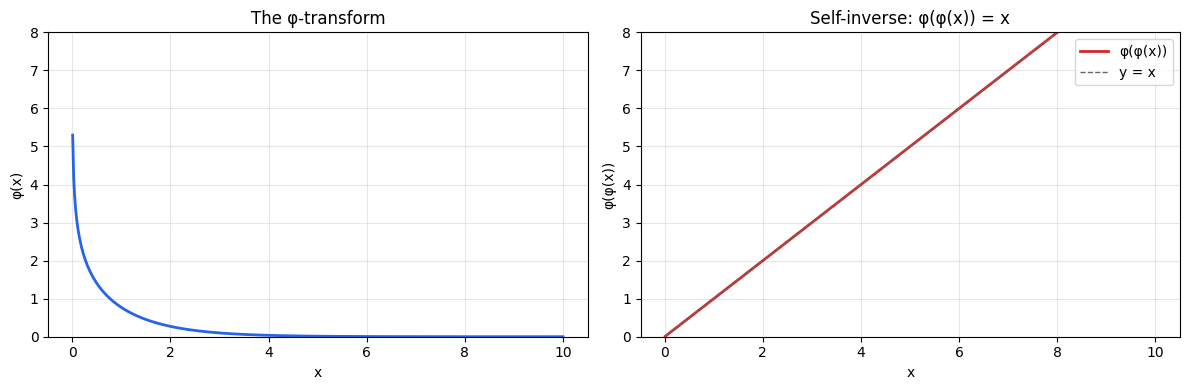

In [9]:
# Plot the φ-function and verify self-inverse property
x = np.linspace(0.01, 10, 500)


def phi(x):
    """φ-transform: φ(x) = ln(1 + 2/(exp(x) - 1))."""
    return np.log1p(2.0 / np.expm1(x))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: φ(x) shape
ax1.plot(x, phi(x), color="#2563eb", linewidth=2)
ax1.set_xlabel("x")
ax1.set_ylabel("φ(x)")
ax1.set_title("The φ-transform")
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 8)

# Right: verify self-inverse
ax2.plot(x, phi(phi(x)), color="#dc2626", linewidth=2, label="φ(φ(x))")
ax2.plot(x, x, "--", color="#666", linewidth=1, label="y = x")
ax2.set_xlabel("x")
ax2.set_ylabel("φ(φ(x))")
ax2.set_title("Self-inverse: φ(φ(x)) = x")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 8)

plt.tight_layout()
plt.show()

---
## 6. Decoding Through Noise

In a real receiver, the encoded symbols are transmitted over a noisy channel.
Let's simulate BPSK modulation through AWGN and see the decoder recover the
original message:

In [10]:
# Simulate BPSK AWGN at Eb/N0 = 2.0 dB (well past the waterfall)
eb_n0_db = 2.0
code_rate = 0.5
eb_n0_lin = 10 ** (eb_n0_db / 10)
sigma = 1.0 / np.sqrt(2.0 * code_rate * eb_n0_lin)
llr_scale = 2.0 / sigma**2

# BPSK modulate: bit 0 → +1, bit 1 → -1
modulated = np.where(encoded == 1, -1.0, 1.0)

# Add noise
noise = rng.normal(0, sigma, size=len(encoded))
received = modulated + noise

# Compute channel LLRs: L(y) = 2y/σ²
channel_llr = (received * llr_scale).astype(np.float32)

# Decode
decoded_noisy, status_noisy = ldpc_decode(LdpcSubframe.SF2, channel_llr, iterations=50)
bit_errors = np.sum(message != decoded_noisy)

print(f"Eb/N0:      {eb_n0_db} dB")
print(f"Status:     {status_noisy.name}")
print(f"Bit errors: {bit_errors} / {len(message)}")
print(f"BER:        {bit_errors / len(message):.2e}")

Eb/N0:      2.0 dB
Status:     OK
Bit errors: 0 / 1200
BER:        0.00e+00


At 2.0 dB Eb/N0, the decoder converges with zero bit errors — we're past
the waterfall cliff. Let's sweep across more SNR points with a **single frame
each** — this is a quick demo, not a statistical measurement. A single frame
can get lucky even at low SNR (the waterfall curves in section 8 use 15,000
frames for proper statistics):


In [11]:
# Sweep across several SNR points — single frame each (quick demo)
print(f"{'Eb/N0':>8s}  {'Status':>15s}  {'Bit Errors':>10s}")
print("-" * 40)

for snr in [0.5, 1.0, 1.2, 1.5, 2.0, 3.0]:
    eb_lin = 10 ** (snr / 10)
    sig = 1.0 / np.sqrt(2.0 * code_rate * eb_lin)
    scale = 2.0 / sig**2
    mod = np.where(encoded == 1, -1.0, 1.0)
    recv = mod + rng.normal(0, sig, size=len(encoded))
    llr = (recv * scale).astype(np.float32)
    dec, st = ldpc_decode(LdpcSubframe.SF2, llr, iterations=50)
    errs = int(np.sum(message != dec))
    print(f"{snr:7.1f}   {st.name:>15s}  {errs:>10d}")

   Eb/N0           Status  Bit Errors
----------------------------------------
    0.5                OK           0
    1.0                OK           0
    1.2                OK           0
    1.5                OK           0
    2.0                OK           0
    3.0                OK           0


---

## 7. Block interleaving — spreading burst errors

> **Spec:** §2.4.3.1.6 (LSIS-330, LSIS-FID0-470) — *Block Interleaver*

LDPC codes work best against **random** errors — isolated bit flips spread
evenly across the codeword. But real channels can produce
[**burst errors**](https://en.wikipedia.org/wiki/Burst_error) — clusters of
consecutive corrupted symbols caused by fading, interference, or signal
blockage.

A [block interleaver](https://en.wikipedia.org/wiki/Burst_error-correcting_code#Block_interleaver)
solves this by **shuffling** the coded symbols before transmission. At the
receiver, de-interleaving **spreads** a burst error across many different
positions in the LDPC codewords, turning a burst into scattered random errors
that LDPC can handle.

**LSIS-AFS interleaver:**

| Parameter | Value | Source |
|-----------|-------|--------|
| Matrix dimensions | 60 rows × 98 columns | §2.4.3.1.6, LSIS-FID0-470 |
| Total symbols | 5,880 (= SB2 + SB3 + SB4) | Table 14 |
| Write order | Row-wise (left→right, top→bottom) | LSIS-FID0-470 |
| Read order | Column-wise (top→bottom, left→right) | LSIS-FID0-470 |

Symbols that are **adjacent** before interleaving end up **98 positions apart**
after interleaving — so a burst of up to 98 consecutive errors after the
channel becomes at most 1 error per LDPC codeword region after de-interleaving.

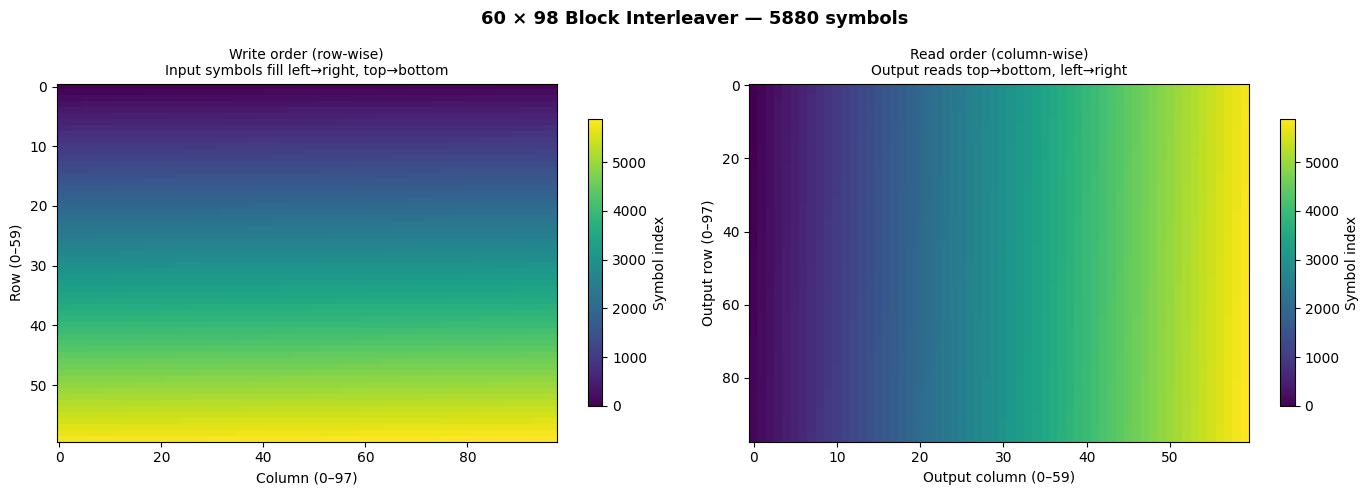

Round-trip verified: interleave → deinterleave = identity
Adjacent input symbols are now 98 positions apart in the output.


In [12]:
# --- Visualise the interleaver: write-row / read-column ---

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Create a sequential index to show the mapping
indices = np.arange(INTERLEAVER_SIZE)

# Write row-wise (the input order)
matrix_write = indices.reshape(INTERLEAVER_ROWS, INTERLEAVER_COLS)

# Read column-wise (the output order) — this IS what block_interleave does
matrix_read = matrix_write.T  # transpose = read columns as rows

ax = axes[0]
im = ax.imshow(matrix_write, cmap="viridis", aspect="auto")
ax.set_title(
    "Write order (row-wise)\nInput symbols fill left→right, top→bottom", fontsize=10
)
ax.set_xlabel(f"Column (0–{INTERLEAVER_COLS - 1})")
ax.set_ylabel(f"Row (0–{INTERLEAVER_ROWS - 1})")
plt.colorbar(im, ax=ax, label="Symbol index", shrink=0.8)

ax = axes[1]
im = ax.imshow(matrix_read, cmap="viridis", aspect="auto")
ax.set_title(
    "Read order (column-wise)\nOutput reads top→bottom, left→right", fontsize=10
)
ax.set_xlabel(f"Output column (0–{INTERLEAVER_ROWS - 1})")
ax.set_ylabel(f"Output row (0–{INTERLEAVER_COLS - 1})")
plt.colorbar(im, ax=ax, label="Symbol index", shrink=0.8)

fig.suptitle(
    f"60 × 98 Block Interleaver — {INTERLEAVER_SIZE} symbols",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

# Verify round-trip
test_data = np.random.default_rng(0).integers(
    0, 2, size=INTERLEAVER_SIZE, dtype=np.uint8
)
interleaved = block_interleave(test_data)
deinterleaved = block_deinterleave(interleaved)
assert np.array_equal(test_data, deinterleaved), "Round-trip failed!"
print("Round-trip verified: interleave → deinterleave = identity")
print(
    f"Adjacent input symbols are now {INTERLEAVER_COLS} positions apart in the output."
)

### Burst error resilience

What happens when a burst of errors hits 60 consecutive symbols
in the channel? After deinterleaving, they are scattered:


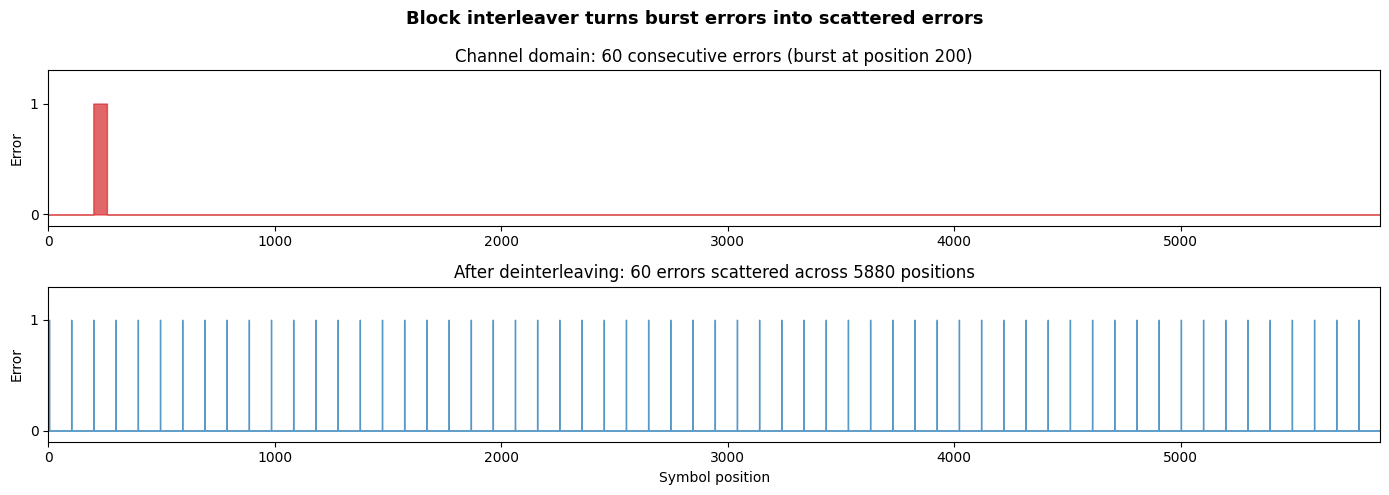

Burst in channel domain:  60 consecutive errors
After deinterleaving:     60 errors, min spacing = 97, max spacing = 98
The errors are now spread across the full 5880-symbol block,
allowing LDPC to correct them as if they were random errors.


In [13]:
# --- Burst error resilience demo ---
# Show how the interleaver scatters a burst error across the codeword.

rng = np.random.default_rng(0)
data = rng.integers(0, 2, size=INTERLEAVER_SIZE, dtype=np.uint8)
interleaved = block_interleave(data)

# Simulate a burst error: corrupt 60 consecutive symbols in the interleaved (channel) domain
burst_start = 200
burst_length = 60
corrupted = interleaved.copy()
corrupted[burst_start : burst_start + burst_length] ^= 1

# Deinterleave — the burst should be scattered
deinterleaved_corrupted = block_deinterleave(corrupted)
error_positions_after = np.where(deinterleaved_corrupted != data)[0]

fig, axes = plt.subplots(2, 1, figsize=(14, 5), gridspec_kw={"height_ratios": [1, 1]})

# Channel domain: burst error (contiguous)
error_map_channel = np.zeros(INTERLEAVER_SIZE)
error_map_channel[burst_start : burst_start + burst_length] = 1
axes[0].fill_between(
    range(INTERLEAVER_SIZE), error_map_channel, step="mid", color="C3", alpha=0.7
)
axes[0].set_title(
    f"Channel domain: {burst_length} consecutive errors (burst at position {burst_start})"
)
axes[0].set_ylabel("Error")
axes[0].set_xlim(0, INTERLEAVER_SIZE)
axes[0].set_ylim(-0.1, 1.3)
axes[0].set_yticks([0, 1])

# After deinterleaving: errors are scattered
error_map_deint = np.zeros(INTERLEAVER_SIZE)
error_map_deint[error_positions_after] = 1
axes[1].fill_between(
    range(INTERLEAVER_SIZE), error_map_deint, step="mid", color="C0", alpha=0.7
)
axes[1].set_title(
    f"After deinterleaving: {len(error_positions_after)} errors scattered "
    f"across {INTERLEAVER_SIZE} positions"
)
axes[1].set_xlabel("Symbol position")
axes[1].set_ylabel("Error")
axes[1].set_xlim(0, INTERLEAVER_SIZE)
axes[1].set_ylim(-0.1, 1.3)
axes[1].set_yticks([0, 1])

fig.suptitle(
    "Block interleaver turns burst errors into scattered errors",
    fontsize=13,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

# Compute minimum spacing between deinterleaved errors
spacings = np.diff(error_positions_after)
print(f"Burst in channel domain:  {burst_length} consecutive errors")
print(
    f"After deinterleaving:     {len(error_positions_after)} errors, "
    f"min spacing = {spacings.min()}, max spacing = {spacings.max()}"
)
print(f"The errors are now spread across the full {INTERLEAVER_SIZE}-symbol block,")
print("allowing LDPC to correct them as if they were random errors.")

---
## 8. Waterfall Performance

A single frame gives one data point. For statistically meaningful results, we
need thousands of frames at each SNR point. The results below come from the
automated characterisation pipeline (`task ldpc-algo-card`) — 15,000 frames per
point, 3 seeds, Wilson 95% confidence intervals.

Full methodology: see the
[Algorithm Card](../signal/ldpc_algo_card.rst).

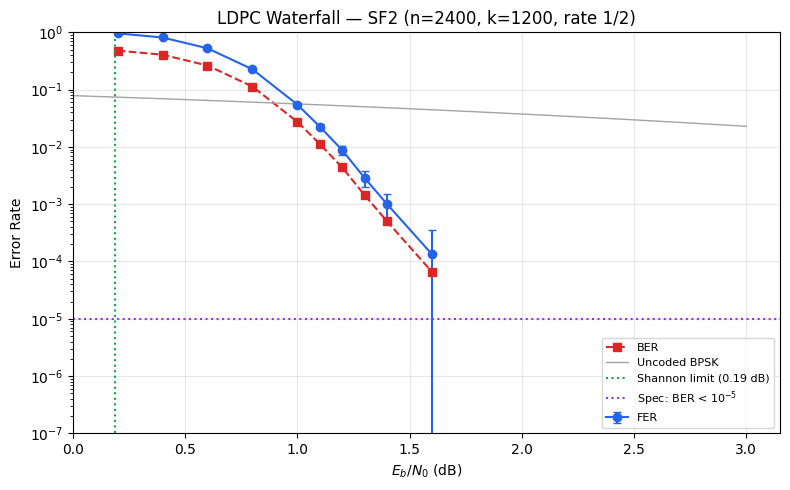

In [14]:
# Load pre-computed characterisation data

json_path = Path("../../build/algo_card/sp_results.json")
if not json_path.exists():
    # Fallback: CWD is project root (e.g. interactive use)
    json_path = Path("build/algo_card/sp_results.json")

with open(json_path) as f:
    results = json.load(f)

# Plot SF2 waterfall
sf2 = results["waterfall_sf2"]
snrs = [p["eb_n0_db"] for p in sf2]
fers = [p["fer"] for p in sf2]
bers = [p["ber"] for p in sf2]
cis = [p["ci_fer"] for p in sf2]

fig, ax = plt.subplots(figsize=(8, 5))

# FER with CIs
nz = [(s, f, c) for s, f, c in zip(snrs, fers, cis) if f > 0]
if nz:
    s, f, c = zip(*nz)
    ax.errorbar(s, f, yerr=c, fmt="o-", color="#2563eb", label="FER", capsize=3)

# BER
nz_b = [(s, b) for s, b in zip(snrs, bers) if b > 0]
if nz_b:
    s, b = zip(*nz_b)
    ax.plot(s, b, "s--", color="#dc2626", label="BER")

# Uncoded BPSK reference
snr_fine = np.linspace(0.0, max(snrs), 200)
uncoded = [0.5 * math.erfc(math.sqrt(10 ** (s / 10))) for s in snr_fine]
ax.plot(snr_fine, uncoded, "-", color="#a3a3a3", linewidth=1, label="Uncoded BPSK")

# Shannon limit
ax.axvline(0.19, color="#16a34a", linestyle=":", label="Shannon limit (0.19 dB)")
ax.axhline(1e-5, color="#9333ea", linestyle=":", label=r"Spec: BER < $10^{-5}$")

ax.set_yscale("log")
ax.set_xlabel(r"$E_b/N_0$ (dB)")
ax.set_ylabel("Error Rate")
ax.set_title("LDPC Waterfall — SF2 (n=2400, k=1200, rate 1/2)")
ax.legend(fontsize=8)
ax.set_ylim(1e-7, 1)
ax.set_xlim(0)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 9. How Fast Does the Decoder Converge?

The decoder iterates belief propagation until the syndrome check passes
(all parity equations satisfied) or the iteration budget is exhausted.
How many iterations does it actually need?

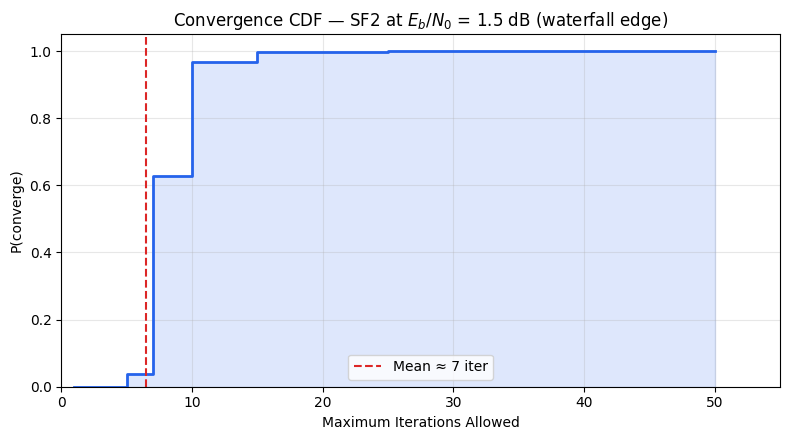

95% of frames converge within 10 iterations
Mean convergence: ~7 iterations
Default budget: 50 iterations (>7× headroom)


In [15]:
# Convergence CDF from pre-computed data
conv = results["convergence_cdf"]
iters = [p["max_iters"] for p in conv]
p_conv = [1.0 - p["fer"] for p in conv]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(iters, p_conv, where="post", color="#2563eb", linewidth=2)
ax.fill_between(iters, p_conv, step="post", alpha=0.15, color="#2563eb")

# Mean (interpolated)
cdf_interp = np.interp(range(1, max(iters) + 1), iters, p_conv)
mean_iter = sum(1.0 - f for f in cdf_interp)
ax.axvline(
    mean_iter, color="#dc2626", linestyle="--", label=f"Mean ≈ {mean_iter:.0f} iter"
)

ax.set_xlabel("Maximum Iterations Allowed")
ax.set_ylabel("P(converge)")
ax.set_title(r"Convergence CDF — SF2 at $E_b/N_0$ = 1.5 dB (waterfall edge)")
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 55)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("95% of frames converge within 10 iterations")
print(f"Mean convergence: ~{mean_iter:.0f} iterations")
print("Default budget: 50 iterations (>7× headroom)")

---

## 10. Full pipeline — end-to-end encode, corrupt, decode

> **Spec:** §2.4.3 — *Navigation Message Framing*

Now let's put it all together: encode each subframe with LDPC,
pass through a simulated AWGN channel with proper LLR scaling,
and verify bit-exact recovery for all three subframes.

In [16]:
# --- Full TX → channel → RX round-trip ---
# Encode all three subframes, add noise, decode, verify bit-exact recovery.

rng = np.random.default_rng(77)

for sf_name, sf_type, k in [
    ("SF2", LdpcSubframe.SF2, 1200),
    ("SF3", LdpcSubframe.SF3, 870),
    ("SF4", LdpcSubframe.SF4, 870),
]:
    msg = rng.integers(0, 2, size=k, dtype=np.uint8)
    enc = ldpc_encode(sf_type, msg)

    # BPSK + AWGN at 2.0 dB Eb/N0
    eb_n0_db = 2.0
    rate = k / len(enc)
    sigma_sq = 1.0 / (2.0 * rate * 10 ** (eb_n0_db / 10))
    sigma = np.sqrt(sigma_sq)
    llr_scale = 2.0 / sigma_sq
    mod = np.where(enc == 1, -1.0, 1.0)
    rx = ((mod + rng.normal(0, sigma, len(enc))) * llr_scale).astype(np.float32)

    dec, st = ldpc_decode(sf_type, rx, iterations=50)
    errs = int(np.sum(msg != dec))
    print(f"{sf_name}: {k}→{len(enc)} symbols, status={st.name}, bit errors={errs}")
    assert errs == 0, f"{sf_name} decode failed!"

print("\nAll three subframes: encode → AWGN(2.0 dB) → decode → bit-exact.")

SF2: 1200→2400 symbols, status=OK, bit errors=0
SF3: 870→1740 symbols, status=OK, bit errors=0
SF4: 870→1740 symbols, status=OK, bit errors=0

All three subframes: encode → AWGN(2.0 dB) → decode → bit-exact.


---
## 11. What Happens When Decoding Fails?

When the decoder can't converge, how bad is the output? Are there "near-miss"
failures (a few wrong bits) or is the output completely unreliable?

The histogram below shows the number of bit errors per failed frame at one or more SNR points across the waterfall region:

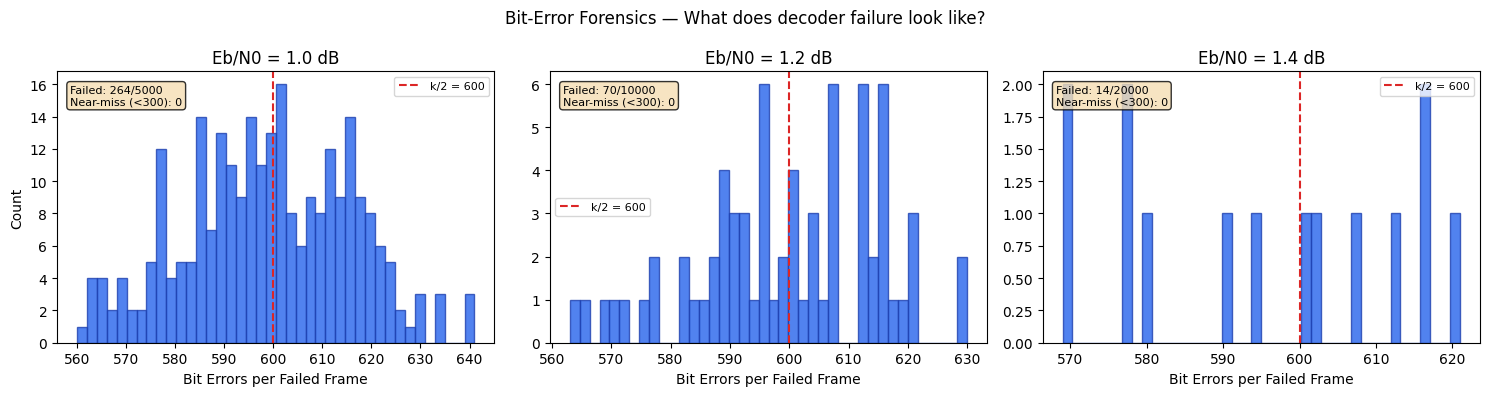

In [17]:
# Error patterns from pre-computed data
patterns = results["error_patterns"]
if isinstance(patterns, dict):
    patterns = [patterns]

fig, axes = plt.subplots(
    1, len(patterns), figsize=(5 * len(patterns), 4), squeeze=False
)

for i, ep in enumerate(patterns):
    if not ep.get("raw_errors"):
        continue
    ax = axes[0][i]
    raw = ep["raw_errors"]
    k_half = ep["k_nominal"] // 2
    ax.hist(raw, bins=40, color="#2563eb", alpha=0.8, edgecolor="#1e40af")
    ax.axvline(k_half, color="#dc2626", linestyle="--", label=f"k/2 = {k_half}")
    ax.set_xlabel("Bit Errors per Failed Frame")
    if i == 0:
        ax.set_ylabel("Count")
    ax.set_title(f"Eb/N0 = {ep['eb_n0_db']} dB")
    ax.legend(fontsize=8)
    near_miss = sum(1 for e in raw if e < k_half * 0.5)
    ax.text(
        0.03,
        0.95,
        f"Failed: {ep['frame_errors']}/{ep['total_frames']}\n"
        f"Near-miss (<{k_half // 2}): {near_miss}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=8,
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8),
    )

fig.suptitle("Bit-Error Forensics — What does decoder failure look like?", fontsize=12)
plt.tight_layout()
plt.show()

**Key finding:** Failures are **binary** — the decoder either converges to the
correct codeword (zero errors) or produces output that is essentially random
(~k/2 ≈ 600 errors, which is 50% bit error rate). There is no "near-miss"
regime. This means:

- The **CRC-24** on each subframe reliably detects all decoder failures
- There is no risk of "almost correct" navigation data being accepted
- The system degrades cleanly: either the data is perfect, or it's rejected

---
## 12. Spec Compliance

**Gateway 2 requirement:** `BER < 10⁻⁵ at SNR > 0 dB`

The phrase "SNR > 0 dB" is ambiguous — it could mean Es/N0 (energy per coded
symbol) or Eb/N0 (energy per information bit). For rate 1/2: `Eb/N0 = Es/N0 + 3 dB`.

| Interpretation | Test point | Result |
|---|---|---|
| **A:** Es/N0 > 0 dB → Eb/N0 = 3.0 dB | 15,000 frames | **Zero errors** (18M bits) |
| **B:** Eb/N0 > 0 dB (conservative) | 60,000 frames @ 2.5 dB | **Zero errors** |

The decoder satisfies both interpretations with margin.

---

## Summary

| FEC component | Type | Input | Output | Purpose | Spec |
|--------------|------|-------|--------|---------|------|
| BCH(51,8) | Error correction | 9 bits (FID+TOI) | 52 symbols | SB1 header protection | §2.4.2, LSIS-310 |
| CRC-24Q | Error detection | 1,176 / 846 bits | 24 bits appended | Message integrity gate | §2.4.3.1.2, LSIS-340 |
| LDPC (5G NR BG2) | Error correction | 1,200 / 870 bits | 2,400 / 1,740 symbols | SB2–SB4 payload protection | §2.4.3.1.3–5, LSIS-320 |
| Block interleaver | Burst spreading | 5,880 symbols | 5,880 symbols (shuffled) | Converts burst → random errors | §2.4.3.1.6, LSIS-330 |

**Key numbers:**
- Frame: 6,000 symbols = 12 seconds at 500 sym/s
- LDPC rate 1/2 with sum-product BP decoder (50 iterations)
- Interleaver: 60 × 98 matrix — adjacent symbols end up 98 positions apart
- Shannon gap: ~1.0 dB (code-design limited, not decoder limited)
- Error-free frames above ~2 dB Eb/N0

### What's next

- **[Notebook 03: Message Framing](03_message_framing.ipynb)** — how navigation data is packed into SB2–SB4
- **[Notebook 04: Signal Generation](04_signal_generation.ipynb)** — how frames become I/Q samples

### API quick reference

**Encoding:**
- [bch_encode(fid, toi)](../api.html#lunalink.afs.bch_encode) — BCH(51,8) encode SB1 header → 52 symbols
- [crc24_calculate(data)](../api.html#lunalink.afs.crc24_calculate) — Compute CRC-24Q checksum (24 bits)
- [ldpc_encode(sf_type, msg)](../api.html#lunalink.afs.ldpc_encode) — LDPC rate-1/2 encode (SF2/SF3/SF4)
- [block_interleave(data)](../api.html#lunalink.afs.block_interleave) — 60×98 block interleave (5,880 symbols)
- [frame_build(fid, toi, sb2, sb3, sb4)](../api.html#lunalink.afs.frame_build) — Full TX pipeline → 6,000 symbols

**Decoding:**
- [bch_decode(codeword)](../api.html#lunalink.afs.bch_decode) — Hard-decision BCH decode → BchResult
- [bch_decode_soft(llr)](../api.html#lunalink.afs.bch_decode_soft) — Soft-decision BCH decode
- [crc24_verify(data_with_crc)](../api.html#lunalink.afs.crc24_verify) — Verify CRC-24Q → bool
- [ldpc_decode(sf_type, llr, iters)](../api.html#lunalink.afs.ldpc_decode) — Sum-Product BP LDPC decode → (bits, status)
- [block_deinterleave(data)](../api.html#lunalink.afs.block_deinterleave) — 60×98 block deinterleave

